# A 350 MHz low-pass on a 1 ns staircase

No Schrödinger equation in this notebook. The only question is what waveform the drive becomes.

"3 dB at 350 MHz" is the cutoff of one analog low-pass, the OPX output stage:

$$
H(s) = \frac{\omega_c}{s + \omega_c}, \qquad \omega_c = 2\pi \times 350\,\mathrm{MHz}.
$$

At $f = 350\,\mathrm{MHz}$, $|H| = 1/\sqrt{2} \approx 0.707$. Power is $|H|^2 = 1/2$, which is $-3\,\mathrm{dB}$.

GRAPE stores one knob per nanosecond. The DAC holds that knob flat. The low-pass chases the hold. It does not emit a new list of 1 ns knobs. The three traces below are:

1. **Knobs.** Flat for 1 ns, then a jump. This is what `sesolve` sees today.
2. **Re-held filter.** One filtered number per nanosecond, held flat again. Still a jump.
3. **Continuous filter.** The exponential chase inside the nanosecond. This is what the `dq.modulated` callback should return.

$I$ and $Q$ each go through this same real filter. The plots use one real channel.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

F_3DB_HZ = 350e6
DT_NS = 1.0
# t is in ns, so omega_c is in rad/ns. 350 MHz * 1 ns = 0.35 cycles.
WC_PER_NS = 2 * np.pi * F_3DB_HZ * 1e-9
A = np.exp(-WC_PER_NS * DT_NS)

print(f"omega_c * 1 ns = {WC_PER_NS:.4f} rad")
print(f"a = exp(-omega_c * dt) = {A:.4f}")
print(f"fraction of a step completed in one nanosecond = {1 - A:.4f}")
print(f"10-90% rise-time estimate 0.35/f_3dB = {0.35 / F_3DB_HZ * 1e9:.3f} ns")

omega_c * 1 ns = 2.1991 rad
a = exp(-omega_c * dt) = 0.1109
fraction of a step completed in one nanosecond = 0.8891
10-90% rise-time estimate 0.35/f_3dB = 1.000 ns


## What the 3 dB point is

A sinusoid at frequency $f$ comes out as the same sinusoid, scaled by

$$
|H(f)| = \frac{1}{\sqrt{1 + (f / f_{3\mathrm{dB}})^2}}.
$$

Slow envelopes (a CR flat-top, a rise stretched over tens of nanoseconds) sit far to the left of 350 MHz, where $|H|\approx 1$. A jump that happens inside one nanosecond has weight out near the cutoff, and that is the part the filter rounds.


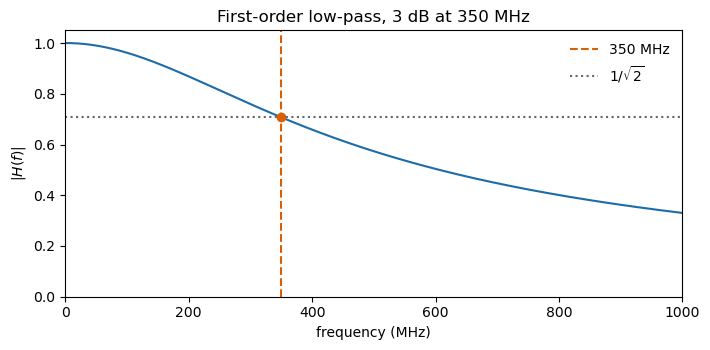

In [2]:
f_mhz = np.linspace(0, 1000, 2000)
h_mag = 1 / np.sqrt(1 + (f_mhz / 350) ** 2)

fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.plot(f_mhz, h_mag, color="#1b6ca8")
ax.axvline(350, color="#d95f02", ls="--", label="350 MHz")
ax.axhline(1 / np.sqrt(2), color="0.4", ls=":", label=r"$1/\sqrt{2}$")
ax.scatter([350], [1 / np.sqrt(2)], color="#d95f02", zorder=3)
ax.set_xlabel("frequency (MHz)")
ax.set_ylabel(r"$|H(f)|$")
ax.set_xlim(0, 1000)
ax.set_ylim(0, 1.05)
ax.legend(frameon=False)
ax.set_title("First-order low-pass, 3 dB at 350 MHz")
fig.tight_layout()
plt.show()

## Inside one 1 ns hold

On the interval $[t_n, t_n + \Delta t)$ the DAC input is the constant knob $x_n$. If the filter output equals $y_n$ at the left edge,

$$
y(t) = x_n + (y_n - x_n)\, e^{-\omega_c (t - t_n)}.
$$

The next left edge is that formula at $\Delta t$:

$$
y_{n+1} = a\, y_n + (1 - a)\, x_n, \qquad a = e^{-\omega_c \Delta t} \approx 0.11.
$$

About 89 percent of the move happens before the next knob. A single stored number has no place to put that curve.

The **re-held** trace takes $y(t)$ at the right edge of each nanosecond and holds it flat across that same nanosecond. That is the array you would drop into `eps_arr` and then index with `floor(t / dt)`.


In [3]:
def left_edges(x, a):
    """y at the left edge of every bin, plus the value at the final right edge."""
    y = np.empty(len(x) + 1, dtype=float)
    y[0] = 0.0
    for n, xn in enumerate(x):
        y[n + 1] = a * y[n] + (1.0 - a) * xn
    return y


def held(t_ns, values, dt_ns=DT_NS):
    """Piecewise-constant view: values[n] on [n, n+1) dt."""
    t_ns = np.asarray(t_ns, dtype=float)
    n = np.floor(t_ns / dt_ns).astype(int)
    n = np.clip(n, 0, len(values) - 1)
    return np.asarray(values, dtype=float)[n]


def continuous(t_ns, x, y_left, dt_ns=DT_NS, wc_per_ns=WC_PER_NS):
    """Analog filter output while the DAC holds x flat."""
    t_ns = np.asarray(t_ns, dtype=float)
    n = np.floor(t_ns / dt_ns).astype(int)
    n = np.clip(n, 0, len(x) - 1)
    tau = t_ns - n * dt_ns
    xn = np.asarray(x, dtype=float)[n]
    yn = np.asarray(y_left, dtype=float)[n]
    return xn + (yn - xn) * np.exp(-wc_per_ns * tau)


def envelope_at(t_ns, x, y_left):
    """Scalar version of continuous(). This is the modulated callback."""
    n = int(np.floor(t_ns / DT_NS))
    n = min(max(n, 0), len(x) - 1)
    tau = t_ns - n * DT_NS
    return x[n] + (y_left[n] - x[n]) * np.exp(-WC_PER_NS * tau)

## A single knob step

The knob sits at 0, then steps to 1 and stays there. Watch the first nanosecond after the step: the blue curve is still climbing at the moment the orange curve has already jumped.


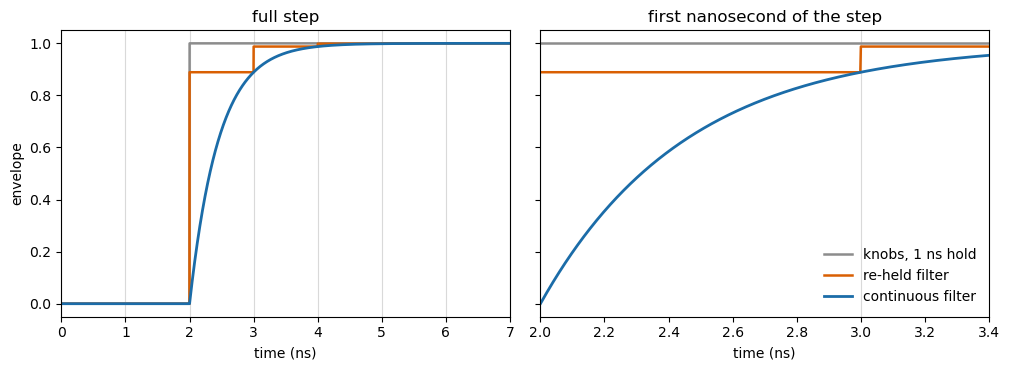

right-edge value after each nanosecond of the step:
[0.     0.     0.8891 0.9877 0.9986 0.9998 1.    ]


In [4]:
step = np.array([0, 0, 1, 1, 1, 1, 1], dtype=float)
y_left_step = left_edges(step, A)
reheld_step = y_left_step[1:]  # value at the right edge of each bin

t_fine = np.linspace(0, len(step) - 1e-6, 4000)

fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.8), sharey=True)

for ax, t_window, title in (
    (axes[0], (0, len(step)), "full step"),
    (axes[1], (2.0, 3.4), "first nanosecond of the step"),
):
    mask = (t_fine >= t_window[0]) & (t_fine <= t_window[1])
    tt = t_fine[mask]
    ax.plot(tt, held(tt, step), color="0.55", lw=1.8, label="knobs, 1 ns hold")
    ax.plot(tt, held(tt, reheld_step), color="#d95f02", lw=1.8, label="re-held filter")
    ax.plot(tt, continuous(tt, step, y_left_step), color="#1b6ca8", lw=2.0, label="continuous filter")
    ax.set_xlim(*t_window)
    ax.set_xlabel("time (ns)")
    ax.set_title(title)
    for n in range(int(t_window[0]), int(np.ceil(t_window[1])) + 1):
        ax.axvline(n, color="0.85", lw=0.8, zorder=0)

axes[0].set_ylabel("envelope")
axes[1].legend(frameon=False, loc="lower right")
fig.tight_layout()
plt.show()

print("right-edge value after each nanosecond of the step:")
print(np.round(reheld_step, 4))

Read the zoom from left to right. At 2 ns the knob jumps from 0 to 1 and stays there. The orange trace jumps at that same instant to the value the filter will only reach at 3 ns (about 0.89), then sits flat. The blue trace starts at 0 and arrives at that 0.89 only at the end of the nanosecond.

So the re-held list is a different pulse from the analog output, and it is still discontinuous. The solver's `floor(t / dt)` indexing cannot see the blue curve, because that curve is not constant on the bin.


## A fast edge and a slow edge

Same three traces. On the left the knob climbs from 0 to 1 in four samples. On the right it takes twenty samples.

The right-hand plot is the closer cartoon of a CR rise. Each step is small, the blue curve barely leaves the gray staircase, and the orange jumps are a small fraction of the amplitude. The left-hand plot is a rise that actually uses the 1 ns grid. There the intra-bin slew is the whole story, and collapsing it to one number per nanosecond puts the jump in the wrong place.


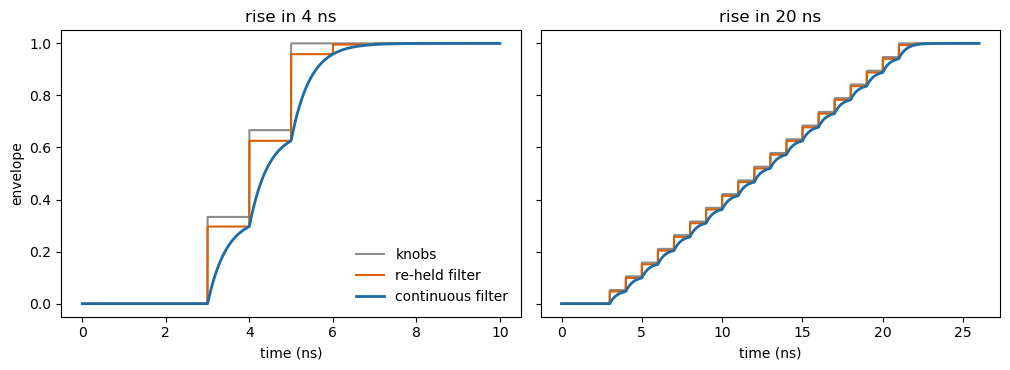

In [5]:
def rising_knobs(n_rise):
    rise = np.linspace(0.0, 1.0, n_rise)
    flat = np.ones(4)
    return np.concatenate([np.zeros(2), rise, flat])


fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.8), sharey=True)
for ax, n_rise, title in (
    (axes[0], 4, "rise in 4 ns"),
    (axes[1], 20, "rise in 20 ns"),
):
    knobs = rising_knobs(n_rise)
    y_left = left_edges(knobs, A)
    tt = np.linspace(0, len(knobs) - 1e-6, 300 * len(knobs))
    ax.plot(tt, held(tt, knobs), color="0.55", lw=1.5, label="knobs")
    ax.plot(tt, held(tt, y_left[1:]), color="#d95f02", lw=1.5, label="re-held filter")
    ax.plot(tt, continuous(tt, knobs, y_left), color="#1b6ca8", lw=2.0, label="continuous filter")
    ax.set_xlabel("time (ns)")
    ax.set_title(title)

axes[0].set_ylabel("envelope")
axes[0].legend(frameon=False, loc="lower right")
fig.tight_layout()
plt.show()

## What the solver should call

Today `_drive_hamiltonian` does `eps_arr[floor(t / dt)]`. That returns the gray staircase.

The filter state is the list `y_left`, one number per knob, filled by the recursion before `sesolve`. At a time $t$ the callback only has to find the bin and evaluate the exponential. There is no second differential equation. $y(t)$ itself does not jump. Its slope jumps when the knob jumps, so the nanosecond boundaries stay in `discontinuity_ts`, which the engine already passes.

The table uses the step waveform. `callback` is the blue curve. `re-held` is the orange one. Inside the bin they differ. At 2.999 ns, still inside the bin that started at 2 ns, the callback has caught the orange value. At 3.0 ns, `floor` has already stepped into the next bin.


In [6]:
print(f"{'t (ns)':>8}  {'knob':>8}  {'re-held':>8}  {'callback':>8}")
for t_ns in (2.0, 2.2, 2.5, 2.999, 3.0, 4.0):
    n = min(int(np.floor(t_ns / DT_NS)), len(step) - 1)
    print(
        f"{t_ns:8.1f}  {step[n]:8.3f}  {reheld_step[n]:8.3f}  "
        f"{envelope_at(t_ns, step, y_left_step):8.3f}"
    )

  t (ns)      knob   re-held  callback
     2.0     1.000     0.889     0.000
     2.2     1.000     0.889     0.356
     2.5     1.000     0.889     0.667
     3.0     1.000     0.889     0.889
     3.0     1.000     0.988     0.889
     4.0     1.000     0.999     0.988


## A saved GRAPE pulse

This is the optimized CR half from `cr_grape_robust_zz0p15MHz_mms_l0p3_20260823_174651.npz` (154 samples, 1 ns each). $I$ and $Q$ are filtered separately. The plot is interactive: scroll to zoom, drag the box-zoom tool for a region, double-click to reset, and drag the strip under the time axis to pan.

Three traces:

1. **GRAPE knobs.** The 1 ns staircase the solver sees today.
2. **Re-held filter.** One filtered number per nanosecond, held flat again. Still discontinuous.
3. **Continuous 350 MHz.** The exponential chase inside each nanosecond.


In [7]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from pathlib import Path

npz_path = Path(
    "/home/hm/IITB/TIFR/Software/Hari_6_qubit/fourqubitv5/HM/simulator/"
    "two_qubit_simulator/optimization/optimization_tests/results/"
    "robust_zz_sweep_dynamiqs/warm/zz_150_kHz/"
    "cr_grape_robust_zz0p15MHz_mms_l0p3_20260823_174651.npz"
)

with np.load(npz_path) as data:
    channels = {
        "I": np.asarray(data["cr_half_opt_I"], dtype=float),
        "Q": np.asarray(data["cr_half_opt_Q"], dtype=float),
    }
    flat_start = int(data["flat_start"])
    fall_start = int(data["fall_start"])

print(npz_path.name)
print(f"samples = {len(channels['I'])}, flat starts at {flat_start} ns, fall starts at {fall_start} ns")


def staircase(values):
    """Hold values[n] on [n, n+1)."""
    x = np.arange(len(values) + 1, dtype=float)
    y = np.concatenate([np.asarray(values, dtype=float), [values[-1]]])
    return x, y


fig = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    vertical_spacing=0.06,
    subplot_titles=("I", "Q"),
)

for row, (name, knobs) in enumerate(channels.items(), start=1):
    y_left = left_edges(knobs, A)
    reheld = y_left[1:]
    t = np.linspace(0.0, len(knobs) - 1e-6, 12 * len(knobs))
    gap = float(np.max(np.abs(y_left[:-1] - knobs)))
    print(f"{name}: largest left-edge gap |y - knob| = {gap:.2f} MHz")

    x_knob, y_knob = staircase(knobs)
    x_held, y_held = staircase(reheld)
    first = row == 1
    fig.add_trace(
        go.Scatter(
            x=x_knob,
            y=y_knob,
            mode="lines",
            line=dict(color="#8a8a8a", width=1.4, shape="hv"),
            name="GRAPE knobs",
            legendgroup="knobs",
            showlegend=first,
        ),
        row=row,
        col=1,
    )
    fig.add_trace(
        go.Scatter(
            x=x_held,
            y=y_held,
            mode="lines",
            line=dict(color="#d95f02", width=1.4, shape="hv"),
            name="re-held filter",
            legendgroup="reheld",
            showlegend=first,
        ),
        row=row,
        col=1,
    )
    fig.add_trace(
        go.Scatter(
            x=t,
            y=continuous(t, knobs, y_left),
            mode="lines",
            line=dict(color="#1b6ca8", width=2),
            name="continuous 350 MHz",
            legendgroup="continuous",
            showlegend=first,
        ),
        row=row,
        col=1,
    )
    fig.update_yaxes(title_text=f"{name} (MHz)", row=row, col=1)

fig.update_xaxes(title_text="time (ns)", row=2, col=1)
fig.update_xaxes(rangeslider=dict(visible=True, thickness=0.05), row=2, col=1)
fig.add_vline(x=flat_start, line_width=1, line_dash="dot", line_color="gray")
fig.add_vline(x=fall_start, line_width=1, line_dash="dot", line_color="gray")
fig.update_layout(
    height=780,
    hovermode="x unified",
    legend=dict(orientation="h", yanchor="bottom", y=1.02, x=0),
    margin=dict(t=70, b=40),
)
fig.show(config={"scrollZoom": True, "displayModeBar": True})


cr_grape_robust_zz0p15MHz_mms_l0p3_20260823_174651.npz
samples = 154, flat starts at 16 ns, fall starts at 138 ns
I: largest left-edge gap |y - knob| = 4.42 MHz
Q: largest left-edge gap |y - knob| = 4.68 MHz
